In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("./cleaned_data.csv")

In [3]:
df.shape

(7032, 27)

In [4]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,Contract_Month-to-month,Contract_One year,Contract_Two year,InternetService_DSL,InternetService_Fiber optic,InternetService_No,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,...,False,True,False,True,False,False,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,...,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,...,False,True,False,True,False,False,True,False,False,False
4,0,0,0,0,2,1,0,0,0,0,...,True,False,False,False,True,False,False,False,True,False


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   7032 non-null   int64  
 1   SeniorCitizen                            7032 non-null   int64  
 2   Partner                                  7032 non-null   int64  
 3   Dependents                               7032 non-null   int64  
 4   tenure                                   7032 non-null   int64  
 5   PhoneService                             7032 non-null   int64  
 6   MultipleLines                            7032 non-null   int64  
 7   OnlineSecurity                           7032 non-null   int64  
 8   OnlineBackup                             7032 non-null   int64  
 9   DeviceProtection                         7032 non-null   int64  
 10  TechSupport                              7032 non-null   in

In [6]:
df.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.504693,0.162400,0.482509,0.298493,32.421786,0.903299,0.421928,0.286547,0.344852,0.343857,0.290102,0.384386,0.388367,0.592719,64.798208,2283.300441,0.265785
std,0.500014,0.368844,0.499729,0.457629,24.545260,0.295571,0.493902,0.452180,0.475354,0.475028,0.453842,0.486484,0.487414,0.491363,30.085974,2266.771362,0.441782
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,35.587500,401.450000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,70.350000,1397.475000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.862500,3794.737500,1.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,118.750000,8684.800000,1.000000


In [7]:
# 1  EDA: tenure guruhlari
# tenure ustunini 4 guruhga bo'ling (0–12, 13–24, 25–48, 49+ oy). Har guruhda ketish foizini hisoblang va ustunli grafik (bar chart) chizing.
# Natija: grafik va 3 ta xulosa jumla

df["tenure_0-12"] = ((df["tenure"] >= 0) & (df["tenure"] <= 12)).astype(int)

df["tenure_13-24"] = ((df["tenure"] > 12) & (df["tenure"] <= 24)).astype(int)

df["tenure_25-48"] = ((df["tenure"] > 24) & (df["tenure"] <= 48)).astype(int)

df["tenure_49+"] = (df["tenure"] > 48).astype(int)

In [8]:
groups = {
    "0-12": df["tenure_0-12"],
    "13-24": df["tenure_13-24"],
    "25-48": df["tenure_25-48"],
    "49+": df["tenure_49+"],
}

churn_rates = {}

for name, mask in groups.items():
    churn_rates[name] = (
        f"{round((df.loc[mask == 1, "Churn"] == True).mean() * 100, 2)}%"
    )

print(pd.Series(churn_rates).round(2))

0-12     47.68%
13-24    28.71%
25-48    20.39%
49+       9.51%
dtype: str


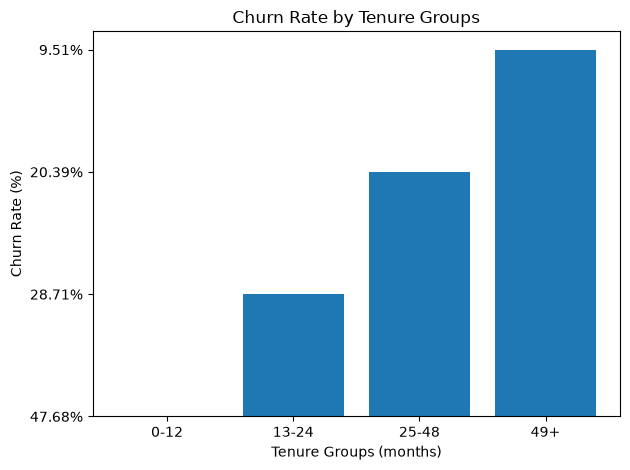

In [9]:
churn_rates = pd.Series(churn_rates)

plt.bar(x=churn_rates.index, height=churn_rates.values)

plt.title("Churn Rate by Tenure Groups")
plt.xlabel("Tenure Groups (months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------------
# bu grafikdan korishimiz mumkinki 0-12 oygacha foydalangan mijozlarning foydalanishni toxtatish foizi eng yuqori bolgan (47.68%)
# 13-24 va 25-48 oygacha foydalangan mijozlarning foydalanishni toxtatish foizi quyidagicha taqsimlangan (28.71% va 20.39%)
# 49+ larda esa 0-12 ga teskari holat kuzatilyabdi yani kop ishlatganlar hali ham kompaniyaga sodiq (9.51%)

In [10]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'tenure_0-12', 'tenure_13-24', 'tenure_25-48', 'tenure_49+'],
      dtype='str')

In [11]:
# 2  Pipeline va 5 model
# Encoding, bo'lish (stratify bilan) va scaling'ni o'zingiz takrorlang. -> scaling lesson.ipynb faylida mustaqil qilingan
# Keyin 5 ta modelni o'rgating: LogReg, Tree, KNN, RF, SVM.
# Natija: 5 ta modelning Accuracy, Precision, Recall, F1, AUC jadvali

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.2, stratify=y)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

classic_algorithms = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(
        max_depth=8, n_estimators=200, random_state=42
    ),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale"),
}

results = []

for name, model in classic_algorithms.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "AUC": roc_auc_score(y_test, y_score),
        }
    )

results_df = pd.DataFrame(results)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
results_df

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.800924,0.641296,0.569231,0.603118,0.840963
1,Decision Tree,0.779417,0.588317,0.565886,0.576884,0.805562
2,KNN,0.771063,0.648069,0.303010,0.412944,0.752983
3,Random Forest,0.796481,0.640449,0.533779,0.582269,0.842756
4,SVM,0.734269,0.000000,0.000000,0.000000,0.799824


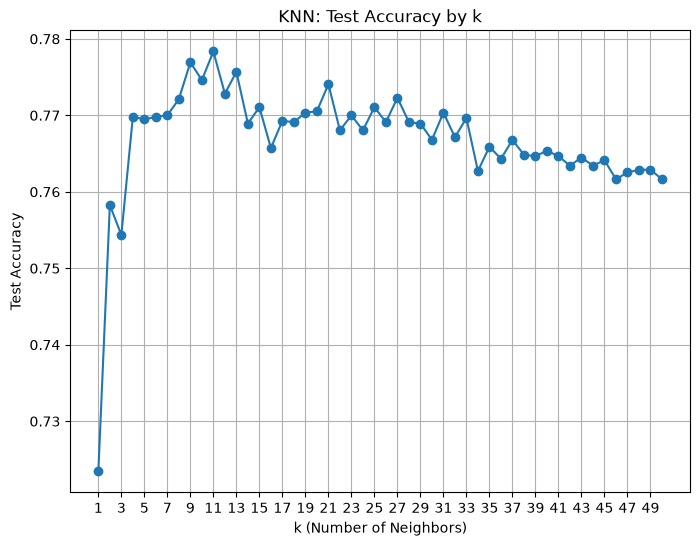

In [15]:
# 3  KNN: eng yaxshi k
# k ni 1 dan 50 gacha o'zgartirib, test accuracy'ni hisoblang va chiziqli grafik chizing.
# Natija: grafik, eng yaxshi k va sababi

ks = range(1, 51)
knn_results = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    knn_results.append(accuracy)

plt.figure(figsize=(8, 6))
plt.plot(ks, knn_results, marker="o")

plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.title("KNN: Test Accuracy by k")

plt.xticks(range(1, 51, 2))
plt.grid(True)
plt.show()

In [16]:
best_index = np.argmax(knn_results)

best_k = list(ks)[best_index]

print("Best k:", best_k)

# -------------------------------------------------------------------------------
# eng yaxshi k = 31 bolyabdi chunki grafikka qarasak ham eng yuqori accuracy test uchun shu nuqtada bolyabdi.

Best k: 11


In [17]:
# 4  Kernel taqqoslash
# SVM'ni kernel = 'linear', 'poly' va 'rbf' bilan o'rgating, natijalarni solishtiring.
# Natija: 3 qatorli jadval va qaysi kernel yaxshiligi sababi

svm_results = []

for kernel in ["rbf", "linear", "poly"]:

    model = SVC(kernel=kernel, C=1.0, gamma="scale")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    svm_results.append({"Kernel": kernel, "Accuracy": accuracy})

svm_results_df = pd.DataFrame(svm_results)

svm_results_df

,Kernel,Accuracy
0,rbf,0.734269
1,linear,0.794348
2,poly,0.734269


In [ ]:
# 5  C va gamma'ni sozlash
# C uchun {0.1, 1, 10, 100}, gamma uchun {0.01, 0.1, 1} qiymatlarini GridSearchCV bilan sinang.
# Natija: C va gamma jadvali (heatmap) hamda eng yaxshi juftlik

from sklearn.model_selection import GridSearchCV

param_grid = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1]}

svm = SVC(kernel="rbf")

grid_search = GridSearchCV(
    estimator=svm, param_grid=param_grid, scoring="accuracy", cv=5, n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'C': 1, 'gamma': 0.1}
Best CV Score: 0.753204108932132


In [ ]:
results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = results.pivot(
    index="param_C", columns="param_gamma", values="mean_test_score"
)

heatmap_data

param_gamma,0.01,0.10,1.00
param_C,,,
0.1,0.739691,0.733997,0.733997
1.0,0.751786,0.753204,0.736844
10.0,0.726900,0.738977,0.732579
100.0,0.720494,0.734714,0.731867


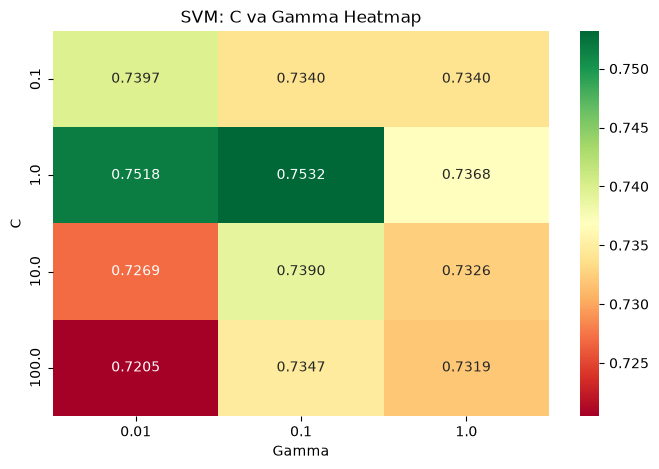

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap="RdYlGn")

plt.title("SVM: C va Gamma Heatmap")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.show()

In [ ]:
# 6  Sinflar og'irligi (class_weight)
# SVM'ga class_weight='balanced' qo'shing. Recall qanchaga o'zgardi? Precision-chi?
# Natija: oldin va keyin jadvali, 2 ta jumla izoh

# Oldingi model
svm_before = SVC(kernel="rbf", C=1.0, gamma="scale")

svm_before.fit(X_train, y_train)
y_pred_before = svm_before.predict(X_test)

# class_weight='balanced' qo'shilgan model
svm_after = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")

svm_after.fit(X_train, y_train)
y_pred_after = svm_after.predict(X_test)

results = pd.DataFrame(
    {
        "Model": ["Before", "After"],
        "Recall": [
            recall_score(y_test, y_pred_before),
            recall_score(y_test, y_pred_after),
        ],
        "Precision": [
            precision_score(y_test, y_pred_before, zero_division=0),
            precision_score(y_test, y_pred_after, zero_division=0),
        ],
    }
)

results

,Model,Recall,Precision
0,Before,0.000000,0.000000
1,After,0.607358,0.375207
